<a href="https://colab.research.google.com/github/dshaurya/BCModel/blob/main/BCDetect.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics roboflow

from roboflow import Roboflow
from ultralytics import YOLO
import ultralytics

ultralytics.checks()

rf = Roboflow(api_key="jXilqOcduSbjz0qFPLf7")

workspace = "image-segmentation-ulmpq"
project_name = "blood-cancer-cell-detection"
version_num = 1

project = rf.workspace(workspace).project(project_name)
dataset = project.version(version_num).download("yolov8")
print("Dataset path:", dataset.location)

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.6/112.6 GB disk)
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Blood-Cancer-Cell-Detection-1 in yolov8:: 100%|██████████| 3216/3216 [00:00<00:00, 6495.33it/s]

Dataset path: /content/Blood-Cancer-Cell-Detection-1


In [ ]:
model = YOLO("yolov8n.pt")
model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    device=0
)

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Blood-Cancer-Cell-Detection-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x780f3116cb30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
from ultralytics import YOLO
import os
import glob
import matplotlib.pyplot as plt
from IPython.display import Image, display

best_path = glob.glob("/content/runs/**/weights/best.pt", recursive=True)[0]
model = YOLO(best_path)

data_root = "/content/Blood-Cancer-Cell-Detection-1"
test_dir = os.path.join(data_root, "test", "images")
valid_dir = os.path.join(data_root, "valid", "images")

img_dir = test_dir if os.path.exists(test_dir) else valid_dir
print("Using:", img_dir)

results = model.predict(
    source=img_dir,
    conf=0.25,
    save=True,
    imgsz=640
)

print("Saved to:", results[0].save_dir)

Using: /content/Blood-Cancer-Cell-Detection-1/test/images

image 1/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Sap_013-9-_jpg.rf.9992cbc1f7ad02dc09d37834864e3e03.jpg: 640x640 1 Benign, 20.5ms
image 2/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_002-3-_jpg.rf.234851712c5c4f33fd9339229e0d6352.jpg: 640x640 1 Benign, 33.3ms
image 3/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_002-Copy_jpg.rf.47aeb75a06913b1c4fe250930f985f06.jpg: 640x640 1 Malignant Pre-B, 10.4ms
image 4/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_003-3-_jpg.rf.29403c9912c92f88e5b068d7838ea425.jpg: 640x640 1 Benign, 38.6ms
image 5/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_004_jpg.rf.77a92cb20fc583bc5e1018222fbe55b7.jpg: 640x640 1 Malignant Pro-B, 14.7ms
image 6/165 /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_007-Copy_jpg.rf.74d2e3c772e31881e3dae1488df424e3.jpg: 640x640 1 Malignant Pre-B, 9.7ms
image 7/165 /content/Blood-Cancer-Cell-Detect

['/content/runs/detect/predict/Snap_672_jpg.rf.15fa862090b6915c8b7fd178b2750ea0.jpg', '/content/runs/detect/predict/Snap_401_jpg.rf.af17a6751f499308cf0b0e0fbba59729.jpg', '/content/runs/detect/predict/Snap_603_jpg.rf.3410330761bf22ec3fc4107b2119f3a7.jpg', '/content/runs/detect/predict/Snap_504_jpg.rf.a7114428c8306b2965c3c7e237d2407b.jpg', '/content/runs/detect/predict/Snap_415_jpg.rf.6c81bfda344e3b64d1a806f9364af577.jpg']


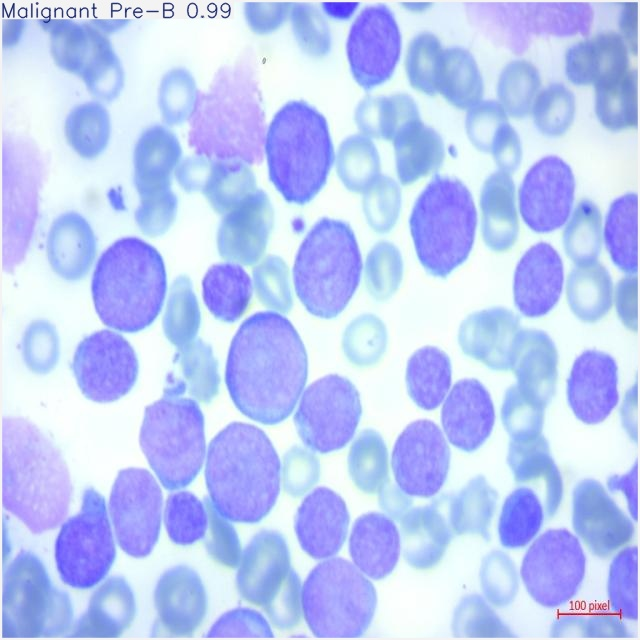

In [ ]:
saved_imgs = glob.glob(f"{results[0].save_dir}/*.jpg")
print(saved_imgs[:5])

display(Image(filename=saved_imgs[0]))

In [ ]:
import os, glob

data_root = "/content/Blood-Cancer-Cell-Detection-1"
img_dir = os.path.join(data_root, "test", "images")
lbl_dir = os.path.join(data_root, "test", "labels")

img_path = glob.glob(f"{img_dir}/*")[0]
base = os.path.splitext(os.path.basename(img_path))[0]
lbl_path = os.path.join(lbl_dir, base + ".txt")

print("Image:", img_path)
print("Label file:", lbl_path)

with open(lbl_path, "r") as f:
    print(f.read())

Image: /content/Blood-Cancer-Cell-Detection-1/test/images/Snap_672_jpg.rf.15fa862090b6915c8b7fd178b2750ea0.jpg
Label file: /content/Blood-Cancer-Cell-Detection-1/test/labels/Snap_672_jpg.rf.15fa862090b6915c8b7fd178b2750ea0.txt
2 0.5 0.50078125 1 0.9984375


In [ ]:
import glob, shutil, os

best_path = glob.glob("/content/runs/**/weights/best.pt", recursive=True)[0]
os.makedirs("/content/exported_model", exist_ok=True)
shutil.copy(best_path, "/content/exported_model/blood_cancer_detector.pt")
print("Saved to /content/exported_model/blood_cancer_detector.pt")

Saved to /content/exported_model/blood_cancer_detector.pt
